# Khumbu Icefall Surface Mapping — Model Training (Sentinel-2 only)

Trains a patch CNN that predicts **snow / ice / debris** on Sentinel-2 crops of the Khumbu Icefall. Glacier **monitoring** (per-scene % cover), **not** avalanche/flood forecasting.

- Data: `data_s2/S2*.tif` (5 real L2A crops, May 2021–Dec 2024, B02/B03/B04/B08/B11) + `*_scl.tif` masks.
- Labels: NDSI starter labels (proxy, not ground truth) with SCL cloud/shadow masking.
- Splits are **by scene** — no patch from a test scene appears in training.
- Nothing from `dataset/` screenshots, Early/Late era, or avalanche folders is used here.

In [1]:
import csv, json, random
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device =', device, '| torch =', torch.__version__)
CLASSES = ['snow', 'ice', 'debris']
SCL_MASK = {0, 1, 3, 7, 8, 9, 10}  # nodata/saturated/shadow/cloud/cirrus

manifest = {r['id']: r for r in json.load(open('data_s2/scenes.json'))}
tifs = sorted(Path('data_s2').glob('S2*.tif'))
tifs = [t for t in tifs if '_scl' not in t.name]
assert len(tifs) >= 1, 'no S2 crops — run s2/download_sentinel2.py first'
for t in tifs:
    m = manifest.get(t.stem, {})
    print(f"{t.stem[:22]} date={m.get('datetime', '?')[:10]} cloud={m.get('cloud_cover', '?')}")

device = cpu | torch = 2.8.0
S2A_45RVL_20221128_0_L date=2022-11-28 cloud=15.041567
S2A_45RVL_20241227_0_L date=2024-12-27 cloud=0.077014
S2A_45RVM_20241227_0_L date=2024-12-27 cloud=0.402756
S2B_45RVL_20230512_0_L date=2023-05-12 cloud=12.373031
S2B_45RVM_20210522_1_L date=2021-05-22 cloud=1.041168


In [2]:
# NDSI calibration: per-scene brightness/NDSI stats justify the thresholds.
# snow = NDSI>0.4 & bright>2000 (winter scenes average ~2100, so gate is 2000 not 4000).
# debris = bright<1200 (deep shadow) OR (NDSI<0 & bright<3000). Else ice.
for t in tifs:
    with rasterio.open(t) as src:
        names = src.tags(ns='s2')['bands'].split(',')
        a = src.read().astype('float32')
    idx = {k: names.index(k) for k in names}
    G, R, NIR, SW = a[idx['green']], a[idx['red']], a[idx['nir']], a[idx['swir16']]
    ndsi = (G - SW) / np.maximum(G + SW, 1.0)
    br = (G + R + NIR) / 3.0
    print(f"{t.stem[4:13]} br_mean={br.mean():.0f} ndsi>0.4={(ndsi > 0.4).mean():.2f} "
          f"ndsi<0={(ndsi < 0).mean():.2f} br<1200={(br < 1200).mean():.2f}")

45RVL_202 br_mean=2051 ndsi>0.4=0.13 ndsi<0=0.79 br<1200=0.38
45RVL_202 br_mean=2175 ndsi>0.4=0.16 ndsi<0=0.72 br<1200=0.30
45RVM_202 br_mean=2154 ndsi>0.4=0.16 ndsi<0=0.72 br<1200=0.30
45RVL_202 br_mean=4282 ndsi>0.4=0.11 ndsi<0=0.44 br<1200=0.08
45RVM_202 br_mean=3040 ndsi>0.4=0.18 ndsi<0=0.73 br<1200=0.06


In [3]:
# Patch generation (S2 + SCL only): 64px, stride 32, >=50% SCL-valid, >=60% majority of valid.
SIZE, STRIDE, PER_CLASS = 64, 32, 600
rng = random.Random(SEED)
kept = []
for tif in tifs:
    with rasterio.open(tif) as src:
        names = src.tags(ns='s2')['bands'].split(',')
        stack = src.read()
    idx = {k: names.index(k) for k in names}
    B, G, R, NIR = stack[idx['blue']], stack[idx['green']], stack[idx['red']], stack[idx['nir']]
    SW = stack[idx['swir16']]
    g, s = G.astype('float32'), SW.astype('float32')
    ndsi = (g - s) / np.maximum(g + s, 1.0)
    br = (G.astype('float32') + R.astype('float32') + NIR.astype('float32')) / 3.0
    pix = np.ones_like(ndsi, dtype=np.int64)
    pix[(ndsi > 0.4) & (br > 2000)] = 0
    pix[(br < 1200) | ((ndsi < 0.0) & (br < 3000))] = 2
    sp = tif.parent / f'{tif.stem}_scl.tif'
    masked = np.zeros_like(pix, dtype=bool)
    if sp.exists():
        with rasterio.open(sp) as sc:
            masked = np.isin(sc.read(1), list(SCL_MASK))
    vis = np.clip(np.stack([R, G, B]).astype('float32') / 6000.0 * 255, 0, 255).astype('uint8').transpose(1, 2, 0)
    H, W = pix.shape
    for y in range(0, H - SIZE + 1, STRIDE):
        for x in range(0, W - SIZE + 1, STRIDE):
            valid = ~masked[y:y + SIZE, x:x + SIZE]
            if valid.mean() < 0.5:
                continue
            vals, counts = np.unique(pix[y:y + SIZE, x:x + SIZE][valid], return_counts=True)
            if counts.max() < 0.6 * valid.sum():
                continue
            kept.append((vis[y:y + SIZE, x:x + SIZE].copy(), int(vals[int(np.argmax(counts))]), tif.stem))
rng.shuffle(kept)
by_cls = {c: [k for k in kept if k[1] == c][:PER_CLASS] for c in range(3)}
print({CLASSES[c]: len(by_cls[c]) for c in by_cls})
# split BY SOURCE SCENE (no leakage)
sources = sorted({s for lst in by_cls.values() for (_, _, s) in lst})
rng.shuffle(sources)
n = len(sources)
test_src, val_src = set(sources[int(0.7 * n):]), set(sources[int(0.5 * n):int(0.7 * n)])
flat = [k for lst in by_cls.values() for k in lst]
splits = {'train': [k for k in flat if k[2] not in val_src | test_src],
          'val': [k for k in flat if k[2] in val_src],
          'test': [k for k in flat if k[2] in test_src]}
Path('data_s2/patches').mkdir(parents=True, exist_ok=True)
with open('data_s2/patches.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['path', 'label', 'class', 'split', 'source'])
    for split, items in splits.items():
        for i, (png, cls, src) in enumerate(items):
            dst = Path(f'data_s2/patches/{split}/{CLASSES[cls]}/{src}_{i:04d}.png')
            dst.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(png).save(dst)
            w.writerow([str(dst), cls, CLASSES[cls], split, src])
        print(f'{split}: n={len(items)}')

{'snow': 169, 'ice': 71, 'debris': 600}
train: n=389
val: n=186
test: n=265


In [4]:
# Dataset (train-only norm, flip/rotation aug on train) + 3-class CNN (~150k params).
class PatchSet(torch.utils.data.Dataset):
    def __init__(self, rows, mean, std, train=False):
        self.rows, self.mean, self.std, self.train = rows, np.array(mean, 'float32'), np.array(std, 'float32'), train
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        p, y = self.rows[i]
        img = Image.open(p).convert('RGB')
        if self.train:
            if random.random() < 0.5: img = img.transpose(Image.FLIP_LEFT_RIGHT)
            img = img.rotate(random.uniform(-10, 10))
        a = (np.asarray(img).astype('float32') / 255.0 - self.mean) / self.std
        return torch.from_numpy(a.transpose(2, 0, 1).astype('float32')), int(y)

class CNN(nn.Module):
    def __init__(self, hidden=128, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2), nn.AdaptiveAvgPool2d((4, 4)))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(64 * 4 * 4, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 3))
    def forward(self, x): return self.head(self.features(x))

rows = {s: [] for s in ('train', 'val', 'test')}
for r in csv.DictReader(open('data_s2/patches.csv')):
    rows[r['split']].append((r['path'], int(r['label'])))
pix = np.concatenate([(np.asarray(Image.open(p).convert('RGB')).astype('float32') / 255.0).reshape(-1, 3)
                      for p, _ in rows['train'][:200]])
MEAN, STD = pix.mean(0).tolist(), (pix.std(0) + 1e-6).tolist()
print('mean', [round(m, 4) for m in MEAN], 'std', [round(s, 4) for s in STD])
print('params:', f"{sum(p.numel() for p in CNN().parameters()):,}")

mean [0.5691, 0.559, 0.5379] std [0.3322, 0.3419, 0.3547]
params: 150,979


In [5]:
# Training: weighted CE, Adam 1e-3, early stop (patience 6) on val macro-F1.
def get_loader(split, train=False, batch=32):
    return torch.utils.data.DataLoader(PatchSet(rows[split], MEAN, STD, train), batch_size=batch, shuffle=train)
tr, va, te = get_loader('train', True), get_loader('val'), get_loader('test')
model = CNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
counts = np.bincount([y for _, y in rows['train']], minlength=3).astype('float32')
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(counts.sum() / (3 * np.maximum(counts, 1))).to(device))

def evaluate(m, loader):
    m.eval(); yp, yt = [], []
    with torch.no_grad():
        for xb, yb in loader:
            yp += m(xb.to(device)).argmax(1).cpu().tolist(); yt += yb.tolist()
    return 100.0 * sum(p == t for p, t in zip(yp, yt)) / len(yt), yp, yt

best, bad, hist = {'f1': -1.0, 'state': None, 'epoch': -1}, 0, {'loss': [], 'f1': []}
for ep in range(25):
    model.train(); tot = 0.0
    for xb, yb in tr:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    hist['loss'].append(tot / len(rows['train']))
    _, yp, yt = evaluate(model, va)
    f1 = f1_score(yt, yp, average='macro', zero_division=0)
    hist['f1'].append(f1)
    print(f'epoch {ep + 1}/25 val_macro_f1={f1:.4f}')
    if f1 > best['f1']:
        best = {'f1': f1, 'state': {k: v.cpu() for k, v in model.state_dict().items()}, 'epoch': ep}; bad = 0
    else:
        bad += 1
        if bad >= 6: break
model.load_state_dict({k: v.to(device) for k, v in best['state'].items()})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist['loss']); ax[0].set_title('Train loss'); ax[0].set_xlabel('epoch')
ax[1].plot(hist['f1']); ax[1].set_title('Val macro-F1'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.savefig('outputs/s2_train_curves.png', dpi=120, bbox_inches='tight')
print('saved outputs/s2_train_curves.png')

epoch 1/25 val_macro_f1=0.7952
epoch 2/25 val_macro_f1=0.6456
epoch 3/25 val_macro_f1=0.7513
epoch 4/25 val_macro_f1=0.7175
epoch 5/25 val_macro_f1=0.7371
epoch 6/25 val_macro_f1=0.6538
epoch 7/25 val_macro_f1=0.6538
saved outputs/s2_train_curves.png


In [6]:
# Held-out test evaluation (run once): accuracy, per-class P/R/F1, confusion matrix.
acc, yp, yt = evaluate(model, te)
rep = classification_report(yt, yp, target_names=CLASSES, digits=4, zero_division=0)
print(f'test acc: {acc:.2f}%\n{rep}')
cm = confusion_matrix(yt, yp, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(CLASSES)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(CLASSES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion — S2 test scenes')
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center')
plt.tight_layout(); plt.savefig('outputs/s2_confusion.png', dpi=120, bbox_inches='tight')
print('saved outputs/s2_confusion.png')
Path('outputs').mkdir(exist_ok=True)
torch.save(model.state_dict(), 'outputs/s2_cnn.pt')
json.dump({'classes': CLASSES, 'config': {'hidden': 128, 'dropout': 0.3, 'lr': 0.001},
           'norm': {'mean': MEAN, 'std': STD}, 'test_accuracy': round(acc, 2),
           'val_macro_f1': round(float(best['f1']), 4), 'report': rep,
           'confusion': cm.tolist()}, open('outputs/s2_results.json', 'w'), indent=2)
print('saved outputs/s2_cnn.pt + outputs/s2_results.json')

test acc: 96.23%
              precision    recall  f1-score   support

        snow     0.9464    0.9815    0.9636        54
         ice     0.9714    0.8095    0.8831        42
      debris     0.9655    0.9941    0.9796       169

    accuracy                         0.9623       265
   macro avg     0.9611    0.9284    0.9421       265
weighted avg     0.9626    0.9623    0.9611       265

saved outputs/s2_confusion.png
saved outputs/s2_cnn.pt + outputs/s2_results.json


In [7]:
# Patch gallery: 3 correct + 3 mistakes per class (expect ice<->debris in shadows).
te_rows = rows['test']
_, yp_all, yt_all = evaluate(model, te)
fig, axes = plt.subplots(3, 6, figsize=(12, 7))
for c in range(3):
    ok = [i for i in range(len(yt_all)) if yt_all[i] == c and yp_all[i] == c][:3]
    bad = [i for i in range(len(yt_all)) if yt_all[i] == c and yp_all[i] != c][:3]
    for k, i in enumerate(ok + bad):
        axes[c, k].imshow(Image.open(te_rows[i][0]))
        axes[c, k].set_title(f"t={CLASSES[yt_all[i]]} p={CLASSES[yp_all[i]]}", fontsize=8)
        axes[c, k].axis('off')
plt.suptitle('Test patches: 3 correct + 3 errors per true class (rows=snow/ice/debris)')
plt.tight_layout(); plt.savefig('outputs/s2_gallery.png', dpi=120, bbox_inches='tight')
print('saved outputs/s2_gallery.png')

saved outputs/s2_gallery.png


S2A_45RVL_20221128_0_L 2022-11-28: snow=10.4% ice=0.7% debris=88.9% (n=144)
S2A_45RVL_20241227_0_L 2024-12-27: snow=10.4% ice=0.7% debris=88.9% (n=144)
S2A_45RVM_20241227_0_L 2024-12-27: snow=9.7% ice=0.7% debris=89.6% (n=144)
S2B_45RVL_20230512_0_L 2023-05-12: snow=25.0% ice=25.0% debris=50.0% (n=48)
S2B_45RVM_20210522_1_L 2021-05-22: snow=20.8% ice=13.9% debris=65.3% (n=144)
saved outputs/s2_cover.csv + outputs/s2_cover_trend.png


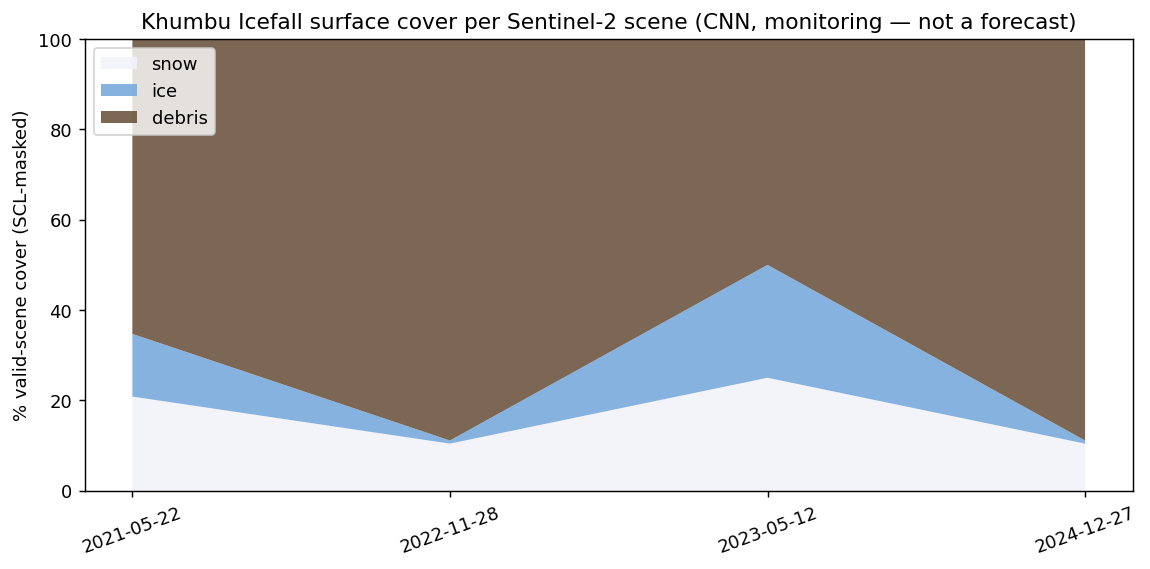

In [8]:
# Full-scene cover maps + trend (SCL-masked). Delegates to s2/cover_trend.py.
!python3 s2/cover_trend.py
from PIL import Image as _I
_I.open('outputs/s2_cover_trend.png')

## Limitations + reproduce

- NDSI starter labels are proxies; expect ice↔debris confusion in shadows (see gallery). A ~200-patch manual audit is the next labeling step.
- Winter scenes read debris-heavy partly from illumination — a shadow/illumination effect, not pure physical change.
- This is surface monitoring, not an avalanche/flood forecast: no lake outlines, no outburst pairs, no event labels.

Reproduce headless: `jupyter nbconvert --to notebook --execute s2_model_training.ipynb --output /tmp/s2_exec.ipynb` or run `s2/download_sentinel2.py → fetch_scl.py → make_patches.py → train_surface_cnn.py → cover_trend.py`.